# Level 1 · Task 3 — K-Nearest Neighbors (KNN) Classifier
**Codveda Technology — Machine Learning Internship**

**Goal:** build a KNN classifier that assigns data points to categories.

**Dataset:** `iris.csv` — 150 iris flowers, 4 measurements (cm), 3 species (setosa, versicolor, virginica).

**Objectives covered**
1. Train a KNN model on a labeled dataset
2. Evaluate it with accuracy, confusion matrix and precision / recall
3. Try different values of K and compare the results

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_score, recall_score, f1_score)

sns.set_theme(style="whitegrid")
IMG = Path("images"); IMG.mkdir(exist_ok=True)
DATA = Path("../../data")
RANDOM_STATE = 42

## 1. Load & explore

In [2]:
df = pd.read_csv(DATA / "iris.csv")
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum(), "| Duplicate rows:", df.duplicated().sum())
print(df["species"].value_counts())
df.head()

Shape: (150, 5)
Missing values: 0 | Duplicate rows: 3
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


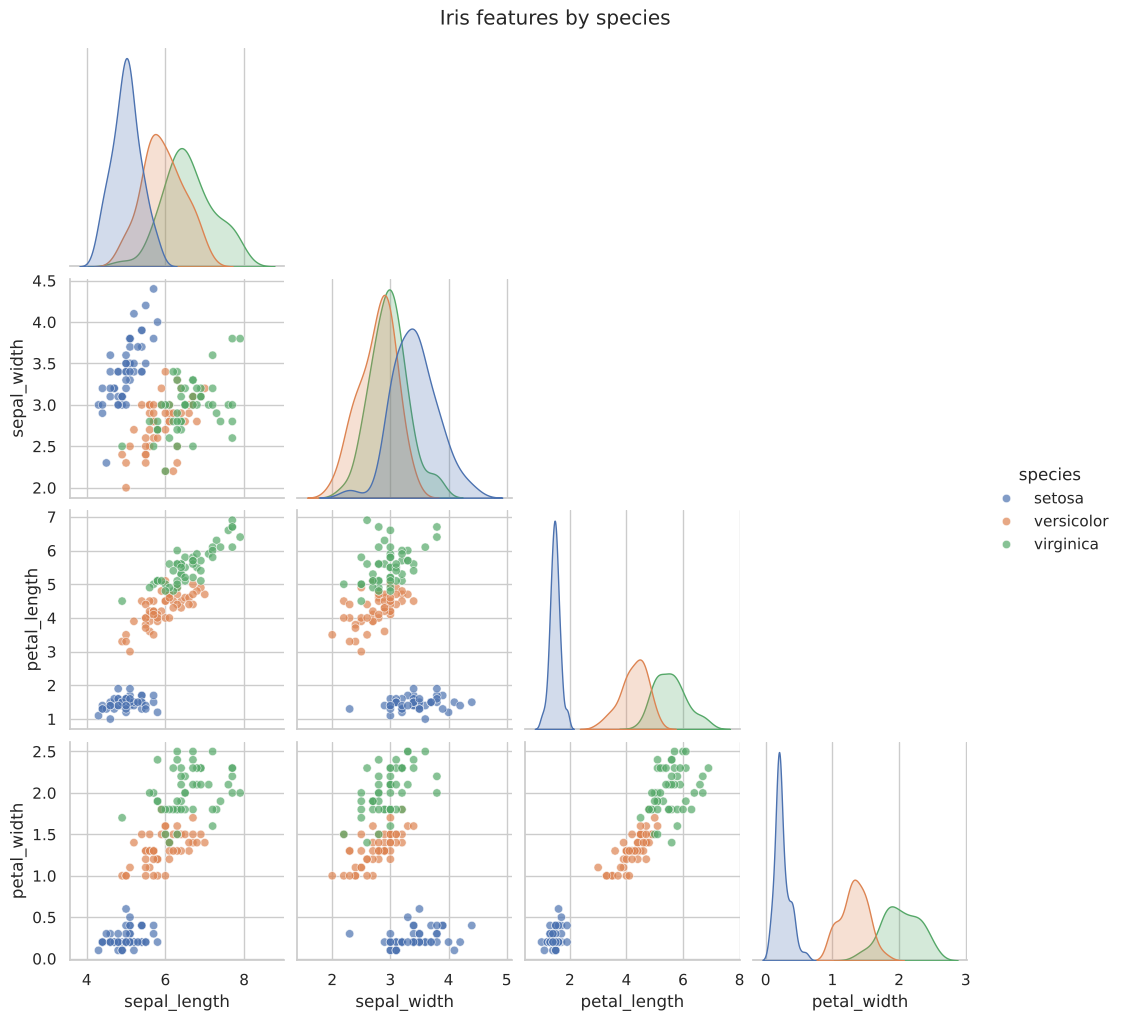

In [3]:
g = sns.pairplot(df, hue="species", corner=True, plot_kws={"alpha": .7})
g.figure.suptitle("Iris features by species", y=1.02)
plt.savefig(IMG / "pairplot.png", dpi=110, bbox_inches="tight"); plt.show()

Petal length and petal width separate the species almost perfectly; *setosa* is completely isolated,
while *versicolor* and *virginica* overlap slightly — that is where any classifier will make its mistakes.

The 3 duplicate rows are genuine flowers with identical measurements (the data is rounded to 0.1 cm), so we keep them.

## 2. Train / test split + scaling
KNN is distance-based, so features must be on the same scale → `StandardScaler` inside a pipeline (fit on train only).

In [4]:
X = df.drop(columns="species")
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (105, 4) | Test: (45, 4)


## 3. Baseline KNN (K = 5)

In [5]:
knn = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))])
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(f"Accuracy (K=5): {accuracy_score(y_test, y_pred):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

Accuracy (K=5): 0.911

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.789     1.000     0.882        15
   virginica      1.000     0.733     0.846        15

    accuracy                          0.911        45
   macro avg      0.930     0.911     0.910        45
weighted avg      0.930     0.911     0.910        45



## 4. Compare different values of K
A single 45-row test set is noisy, so besides test accuracy we also use **10-fold stratified cross-validation on the training set**
to choose K — the test set is kept for the final, unbiased check.

In [6]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
rows = []
for k in range(1, 31):
    pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))])
    cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"K": k,
                 "train_acc": pipe.score(X_train, y_train),
                 "cv_acc": cv_scores.mean(), "cv_std": cv_scores.std(),
                 "test_acc": accuracy_score(y_test, pred),
                 "test_precision_macro": precision_score(y_test, pred, average="macro"),
                 "test_recall_macro": recall_score(y_test, pred, average="macro")})
k_results = pd.DataFrame(rows)
k_results[k_results["K"].isin([1, 3, 5, 7, 9, 11, 15, 21, 25, 30])].round(3)

,K,train_acc,cv_acc,cv_std,test_acc,test_precision_macro,test_recall_macro
0,1,1.000,0.952,0.077,0.933,0.944,0.933
2,3,0.971,0.973,0.058,0.911,0.930,0.911
4,5,0.981,0.953,0.077,0.911,0.930,0.911
6,7,0.981,0.972,0.059,0.933,0.944,0.933
8,9,0.971,0.972,0.059,0.956,0.961,0.956
10,11,0.971,0.972,0.059,0.956,0.961,0.956
14,15,0.981,0.945,0.073,0.933,0.935,0.933
20,21,0.962,0.917,0.095,0.889,0.898,0.889
24,25,0.914,0.890,0.120,0.889,0.898,0.889
29,30,0.886,0.879,0.101,0.867,0.882,0.867


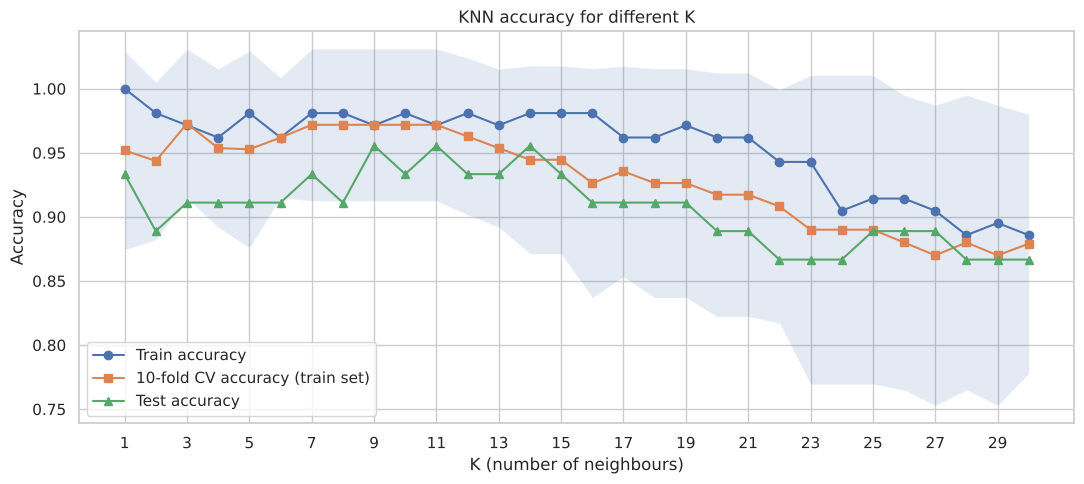

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(k_results["K"], k_results["train_acc"], "o-", label="Train accuracy")
ax.plot(k_results["K"], k_results["cv_acc"], "s-", label="10-fold CV accuracy (train set)")
ax.fill_between(k_results["K"], k_results["cv_acc"] - k_results["cv_std"],
                k_results["cv_acc"] + k_results["cv_std"], alpha=.15)
ax.plot(k_results["K"], k_results["test_acc"], "^-", label="Test accuracy")
ax.set_xlabel("K (number of neighbours)"); ax.set_ylabel("Accuracy")
ax.set_title("KNN accuracy for different K"); ax.legend(); ax.set_xticks(range(1, 31, 2))
plt.tight_layout(); plt.savefig(IMG / "k_comparison.png", dpi=120); plt.show()

In [8]:
# K = 3 and K = 7…11 are practically tied on CV accuracy (differences < 0.5 %).
# Rule: among the K values within 0.005 of the best CV score, take the LARGEST odd K —
# a larger K averages over more neighbours, so it is smoother and less sensitive to noisy points.
best_cv = k_results["cv_acc"].max()
candidates = k_results[(k_results["cv_acc"] >= best_cv - 0.005) & (k_results["K"] % 2 == 1)]
print(candidates[["K", "cv_acc", "cv_std"]].round(3).to_string(index=False))
best = candidates.sort_values("K").iloc[-1]
best_k = int(best["K"])
print(f"\nSelected K = {best_k} (CV accuracy {best['cv_acc']:.3f} ± {best['cv_std']:.3f})")

 K  cv_acc  cv_std
 3   0.973   0.058
 7   0.972   0.059
 9   0.972   0.059
11   0.972   0.059

Selected K = 11 (CV accuracy 0.972 ± 0.059)


## 5. Final model — evaluation with the selected K

In [9]:
final = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=best_k))])
final.fit(X_train, y_train)
y_pred = final.predict(X_test)

print(f"Test accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision (macro): {precision_score(y_test, y_pred, average='macro'):.3f}")
print(f"Recall    (macro): {recall_score(y_test, y_pred, average='macro'):.3f}")
print(f"F1        (macro): {f1_score(y_test, y_pred, average='macro'):.3f}\n")
print(classification_report(y_test, y_pred, digits=3))

Test accuracy : 0.956
Precision (macro): 0.961
Recall    (macro): 0.956
F1        (macro): 0.955

              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.882     1.000     0.938        15
   virginica      1.000     0.867     0.929        15

    accuracy                          0.956        45
   macro avg      0.961     0.956     0.955        45
weighted avg      0.961     0.956     0.955        45



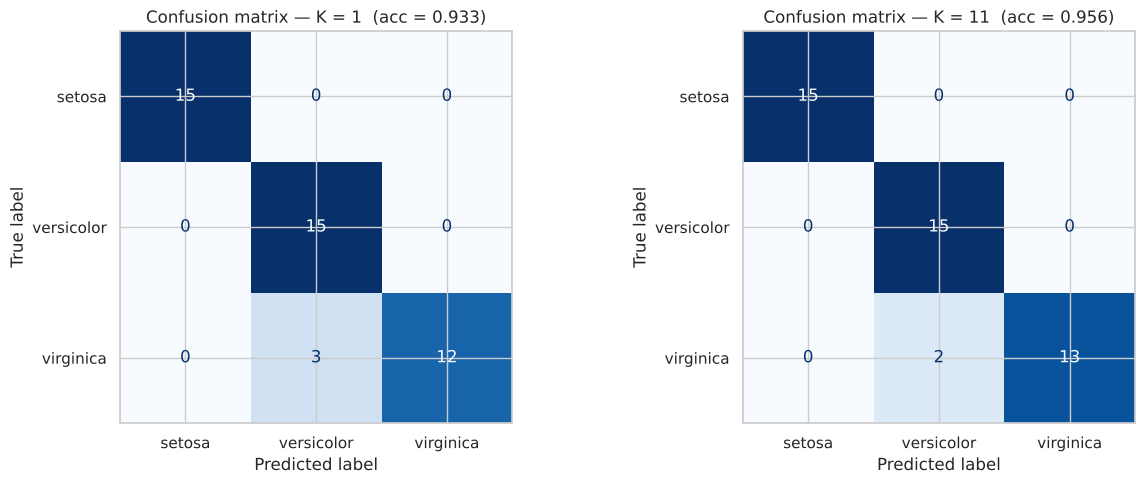

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, k in zip(axes, [1, best_k]):
    m = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))]).fit(X_train, y_train)
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix — K = {k}  (acc = {m.score(X_test, y_test):.3f})")
plt.tight_layout(); plt.savefig(IMG / "confusion_matrices.png", dpi=120); plt.show()

## 6. Visualising the decision regions (petal features)
Fit on the two petal features only so the boundaries can be drawn in 2-D.

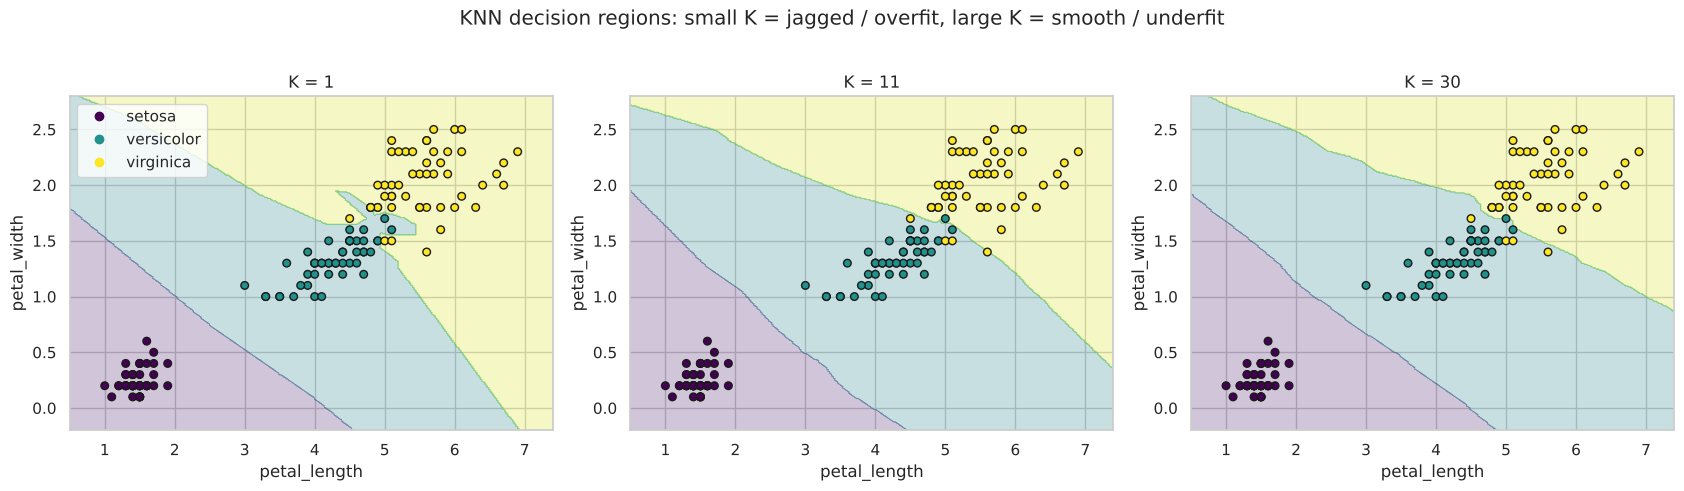

In [11]:
feat = ["petal_length", "petal_width"]
species = sorted(y.unique())
y_codes = y.map({s: i for i, s in enumerate(species)})
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, k in zip(axes, [1, best_k, 30]):
    m = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k))]).fit(X[feat], y_codes)
    xx, yy = np.meshgrid(np.linspace(X[feat[0]].min() - .5, X[feat[0]].max() + .5, 300),
                         np.linspace(X[feat[1]].min() - .3, X[feat[1]].max() + .3, 300))
    zz = m.predict(pd.DataFrame(np.c_[xx.ravel(), yy.ravel()], columns=feat)).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=.25, cmap="viridis")
    sc = ax.scatter(X[feat[0]], X[feat[1]], c=y_codes, cmap="viridis", edgecolor="k", s=30)
    ax.set_title(f"K = {k}"); ax.set_xlabel(feat[0]); ax.set_ylabel(feat[1])
axes[0].legend(sc.legend_elements()[0], species, loc="upper left")
plt.suptitle("KNN decision regions: small K = jagged / overfit, large K = smooth / underfit", y=1.02)
plt.tight_layout(); plt.savefig(IMG / "decision_regions.png", dpi=120, bbox_inches="tight"); plt.show()

## Conclusions
* **K matters.** `K = 1` memorises the training set (train accuracy 100 %) and draws jagged boundaries; very large K (≥ 21)
  over-smooths and accuracy drops below 90 %. The sweet spot is **K ≈ 7–11**, where cross-validated accuracy is ~97 %.
* **Selected model: K = 11** (chosen with cross-validation only, not the test set) → **test accuracy 95.6 %**,
  macro precision 0.96, macro recall 0.96.
* The confusion matrices show that *setosa* is always classified perfectly; the only errors are between
  *versicolor* and *virginica*, the two species whose petal measurements overlap.
* With only 45 test flowers, one misclassification changes accuracy by 2.2 points, which is why cross-validation
  (not a single test score) was used to compare values of K.